python -m venv .venv

.venv\Scripts\Activate.ps1

pip install ipykernel kagglehub pandas numpy scikit-learn matplotlib

Add-Content .gitignore ".venv/"

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mkhoirulmustaqim/student-depression-detection-dataset")

print("Path to dataset files:", path)

/Users/jasper_laptop/Class/Student_depression_classifier-/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/jasper_laptop/.cache/kagglehub/datasets/mkhoirulmustaqim/student-depression-detection-dataset/versions/1


In [22]:
import pandas as pd
import numpy as np
import sklearn 
import matplotlib.pyplot as plt
data = pd.read_csv("Student_Depression_Dataset.csv")
print(data)

      Gender  Age   Family_background Relationship_status Marital_status  \
0     Female   22        Middle class              Single      Unmarried   
1       Male   19        Middle class              Single      Unmarried   
2       Male   23        Middle class              Single      Unmarried   
3       Male   20        Middle class         Complicated      Unmarried   
4     Female   21        Middle class              Single      Unmarried   
...      ...  ...                 ...                 ...            ...   
4459  Female   26        Middle class   In a Relationship      Separated   
4460    Male   28  Lower Middle class              Single      Unmarried   
4461  Female   23        Middle class   In a Relationship        Married   
4462  Female   23        Middle class         Complicated        Married   
4463  Female   21  Lower Middle class              Single      Unmarried   

     Living_style  Current_semester  CGPA friend_circle Health_condition  \
0        Ba

['Gender', 'Age', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'Current_semester', 'CGPA', 'friend_circle', 'Health_condition', 'Cost_without_study', 'Home_division', 'Depression']
4464


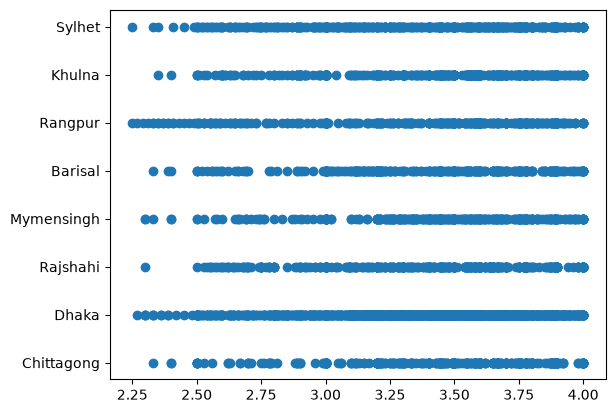

In [32]:
lst_features =list(data.columns)
len_of_data = data['Gender'].count()
print(lst_features)
print(len_of_data)

plt.scatter(data["CGPA"],data["Home_division"])

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# CGPA distribution
axes[0, 0].hist(data["CGPA"], bins=20, edgecolor="black")
axes[0, 0].set(title="CGPA Distribution", xlabel="CGPA", ylabel="Number of Students")

# Age vs. CGPA, grouped by depression status
for status, group in data.groupby("Depression"):
    axes[0, 1].scatter(group["Age"], group["CGPA"], alpha=0.5, label=status)
axes[0, 1].set(title="Age vs. CGPA by Depression Status", xlabel="Age", ylabel="CGPA")
axes[0, 1].legend(title="Depression")

# Depression counts
data["Depression"].value_counts().plot(kind="bar", ax=axes[1, 0], color="steelblue")
axes[1, 0].set(title="Students by Depression Status", xlabel="Depression", ylabel="Number of Students")
axes[1, 0].tick_params(axis="x", rotation=0)

# CGPA by depression status
data.boxplot(column="CGPA", by="Depression", ax=axes[1, 1])
axes[1, 1].set(title="CGPA by Depression Status", xlabel="Depression", ylabel="CGPA")
fig.suptitle("")

plt.tight_layout()
plt.show()